# 02. Анализ: ответы на три вопроса

1. Как связаны длина и глубина клюва?
2. Различается ли масса самцов и самок у вида Adelie?
3. Можно ли определить вид пингвина только по размерам клюва?

In [11]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt  # базовая библиотека графиков
import seaborn as sns  # статистические графики
from scipy import stats  # статистические критерии
from sklearn.dummy import DummyClassifier  # «глупая» модель для сравнения
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay  # картинка матрицы ошибок
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.pipeline import make_pipeline  # склейка шагов в одну модель
from sklearn.preprocessing import StandardScaler  # стандартизация признаков

from palmer_penguins.data import PROJECT_ROOT, load_clean

FIG = PROJECT_ROOT / "reports" / "figures"
df = load_clean()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Вопрос 1. Длина и глубина клюва: парадокс Симпсона

Меру линейной связи даёт **коэффициент корреляции Пирсона**:

$$
r = \frac{\sum_{i}(x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_{i}(x_i-\bar x)^2}\,\sqrt{\sum_{i}(y_i-\bar y)^2}} \in [-1, 1].
$$

Это косинус угла между центрированными векторами $x-\bar x$ и $y-\bar y$. Знак показывает направление связи.

In [12]:
# Корреляция по ВСЕМ птицам сразу, без учёта вида.
df["bill_length_mm"].corr(df["bill_depth_mm"])

np.float64(-0.2350528703555326)

In [13]:
# Та же корреляция, но ОТДЕЛЬНО внутри каждого вида.
df.groupby("species", observed=True)[["bill_length_mm", "bill_depth_mm"]].corr()

bill_length_mm  bill_depth_mm
species                                                
Adelie    bill_length_mm        1.000000       0.391492
          bill_depth_mm         0.391492       1.000000
Chinstrap bill_length_mm        1.000000       0.653536
          bill_depth_mm         0.653536       1.000000
Gentoo    bill_length_mm        1.000000       0.643384
          bill_depth_mm         0.643384       1.000000

По всем птицам $r \approx -0.24$ (чем длиннее клюв, тем он мельче), а **внутри каждого вида** связь положительная: $r \approx 0.39$ у Adelie, $0.65$ у Chinstrap, $0.64$ у Gentoo. При объединении групп зависимость **сменила знак** — это парадокс Симпсона.

Причина — разложение ковариации на внутригрупповую и межгрупповую части:

$$
\operatorname{cov}(x,y) = \underbrace{\sum_g \tfrac{n_g}{n}\operatorname{cov}_g(x,y)}_{>0\ \text{внутри видов}} + \underbrace{\sum_g \tfrac{n_g}{n}(\bar x_g-\bar x)(\bar y_g-\bar y)}_{<0\ \text{между видами}}.
$$

Центры облаков разных видов расположены так, что межгрупповое слагаемое отрицательно и перевешивает. Вид здесь влияет на оба признака сразу.

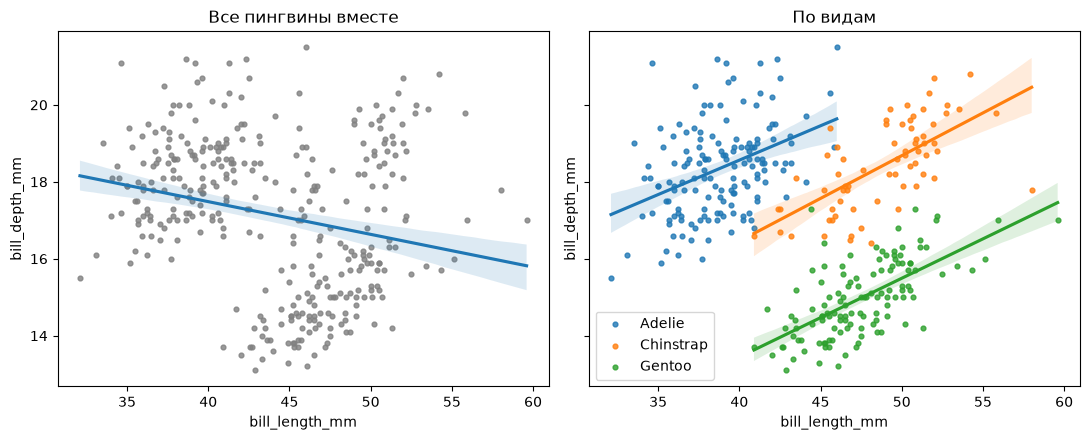

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)

sns.regplot(
    data=df,
    x="bill_length_mm",
    y="bill_depth_mm",
    ax=axes[0],
    scatter_kws={"s": 12, "color": "gray"},
)
axes[0].set_title("Все пингвины вместе")

for species, part in df.groupby("species", observed=True):
    sns.regplot(
        data=part,
        x="bill_length_mm",
        y="bill_depth_mm",
        ax=axes[1],
        label=species,
        scatter_kws={"s": 12},
    )
axes[1].set_title("По видам")
axes[1].legend()

fig.tight_layout()
fig.savefig(FIG / "simpson.png", dpi=120)

**Вывод 1.** Прежде чем делать выводы о связи признаков, нужно искать скрытые группы. Внутри вида крупная особь крупна во всём (длина и глубина клюва растут вместе); общая отрицательная корреляция - артефакт смешения видов.

## Вопрос 2. Масса самцов и самок Adelie: t-критерий Уэлча

Сравниваем внутри одного вида, чтобы различия между видами не смешались с различием полов.

Гипотеза $H_0:\ \mu_1 = \mu_2$ (средние массы самцов и самок равны). Статистика Уэлча:

$$
t = \frac{\bar X - \bar Y}{\sqrt{\dfrac{s_1^2}{n_1} + \dfrac{s_2^2}{n_2}}},
$$

в знаменателе - оценка стандартного отклонения разности средних. В отличие от классического критерия Стьюдента, Уэлч не требует равенства дисперсий групп.

In [15]:
adelie = df[df["species"] == "Adelie"].dropna(subset=["sex"])

males = adelie.loc[adelie["sex"] == "male", "body_mass_g"]
females = adelie.loc[adelie["sex"] == "female", "body_mass_g"]

print(f"самцы: n={len(males)}, среднее {males.mean():.0f} г")
print(f"самки: n={len(females)}, среднее {females.mean():.0f} г")

самцы: n=73, среднее 4043 г
самки: n=73, среднее 3369 г


In [16]:
# equal_var=False — это и есть вариант Уэлча (дисперсии не предполагаются равными).
res = stats.ttest_ind(males, females, equal_var=False)
print(res)  # статистика t, p-значение и число степеней свободы df

# 95%-доверительный интервал для разности средних (самцы минус самки).
print(res.confidence_interval(0.95))

TtestResult(statistic=np.float64(13.126285923485874), pvalue=np.float64(6.402319748031804e-26), df=np.float64(135.69357893530383))
ConfidenceInterval(low=np.float64(573.0139063399297), high=np.float64(776.301162153221))


**Вывод 2.** Самцы Adelie тяжелее самок в среднем примерно на 675 г: $t \approx 13.1$, $p \approx 6\cdot 10^{-26}$, 95%-доверительный интервал разности $\approx [573;\ 776]$ г.

Интервал информативнее p-значения: он говорит не только «разница есть», но и **насколько она велика**. Маленькое $p$ само по себе не означает большой эффект.

## Вопрос 3. Можно ли определить вид по размерам клюва

Возьмем простую модель - **логистическую регрессию**. Для каждого вида $k$ линейная функция $z_k = w_k^\top x + b_k$, вероятности - через softmax:

$$
P(y = k \mid x) = \frac{e^{z_k}}{\sum_{j} e^{z_j}}.
$$

Качество оцениваем **кросс-валидацией** на 5 частях и сравниваем с "глупой" моделью, которая всегда называет самый частый вид.

In [17]:
X = df[["bill_length_mm", "bill_depth_mm"]]
y = df["species"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

baseline = cross_val_score(DummyClassifier(strategy="most_frequent"), X, y, cv=cv)

# Стандартизация внутри пайплайна, так среднее и разброс считаются только
# по обучающей части каждого разбиения - иначе была бы утечка данных.
model = make_pipeline(StandardScaler(), LogisticRegression())
scores = cross_val_score(model, X, y, cv=cv)

print(f"baseline: {baseline.mean():.3f}")
print(f"модель:   {scores.mean():.3f} ± {scores.std():.3f}")

baseline: 0.442
модель:   0.962 ± 0.022


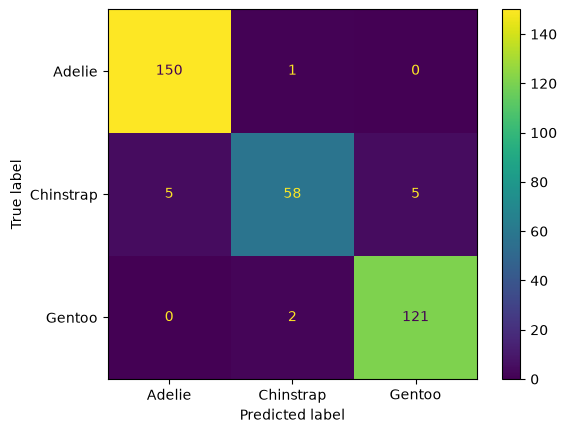

In [18]:
pred = cross_val_predict(model, X, y, cv=cv)

disp = ConfusionMatrixDisplay.from_predictions(y, pred)
disp.figure_.savefig(FIG / "confusion.png", dpi=120)

In [19]:
# Та же модель, но только по длине клюва.
only_length = cross_val_score(model, df[["bill_length_mm"]], y, cv=cv)
print(f"только длина: {only_length.mean():.3f}")

только длина: 0.760


**Вывод 3.** По двум размерам клюва логистическая регрессия угадывает вид в ≈96% случаев против ≈44% у константной модели. Чаще всего ошибается на Chinstrap, так как по длине клюва они похожи на Gentoo, а по глубине - на Adelie.

По одной длине клюва точность падает до ≈76%, так как длина отделяет Adelie, но не различает Chinstrap и Gentoo — их разделяет глубина. Два признака вместе дают то, чего не даёт ни один по отдельности.

Какая модель лучше и значимы ли различия между моделями — в `03_models.ipynb`.